# Explaining the final model on the ten delivered promoters

Four explanations of the model behind our wet-lab panel, run on the same
twelve sequences: ten synthetic designs and the two native anchors they are
scored against.

1. **In-silico mutagenesis** - substitute every base, measure how far the
   prediction moves. No gradients, no attributions, no linearity assumed.
2. **Per-level ablation** - silence one level of the code ladder at a time.
   Each level is a length scale (32 bp at L0 down to 2 bp at L4), so the
   answer is about *scale*, not an anonymous channel.
3. **Motif occupancy** — which of the 252 frozen PWM profiles the designs
   gained or lost against the promoter they came from.
4. **Do the edits land where the model looks?** - a self-consistency check on
   the design pipeline, which can fail.

**Held fixed.** Only the DNA varies: the strain is pinned to P1 and the other
conditioning channels answer with their learned "unknown" token. Every number
below is the *sequence* contribution alone, not a predicted strength of those
come from the panel pipeline, which scores each candidate in both reporter
constructs.

In [1]:
%matplotlib inline
import json
import os
import sys

import numpy as np
import torch

REPO = os.path.abspath(os.path.join(os.getcwd(), ".."))
for p in (os.path.join(REPO, "src"), os.path.join(REPO, "src", "panel")):
    if p not in sys.path:
        sys.path.insert(0, p)
os.environ.setdefault("HYPPE_DATA_ROOT", os.environ.get("HYPPE_DATA_ROOT", REPO))

import model_io

from hyppe.data.sequences import NUCLEOTIDE_ORDER

BASES = NUCLEOTIDE_ORDER                      # "ACGT" in this repository
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("repo   :", REPO)
print("device :", DEVICE)
print("alphabet:", BASES, "- the complement is a reversal of the channel axis")


repo   : /mnt/c/Nauka/Studia/Projekty/Projekt-BW/KAAMMB/HYPPE/HYperbolicPromoterProgrammingEngine
device : cuda
alphabet: ACGT - the complement is a reversal of the channel axis


## 1. The model, and which model it is

A result is interpretable only next to the checkpoint that produced it, so the
file's own hash and the configuration recorded inside it are printed first.
`load_model` refuses on any state-dict key mismatch, and that refusal is the
point: a model built from a slightly different config loads "successfully" and
then reports the metrics of a different architecture.

In [2]:
CKPT = os.environ.get(
    "HYPPE_CKPT", os.path.join(REPO, "weights", "hyppe_foundational.pt"))
assert os.path.exists(CKPT), (
    "No checkpoint at %s. The delivered weights ship in weights/; set "
    "HYPPE_CKPT to explain a different model." % CKPT)

model, prov = model_io.load_model(CKPT, device=DEVICE)
model.eval()
print(prov.one_line())
print("sha256  :", model_io.sha256(CKPT)[:16], "...")
print("params  :", sum(p.numel() for p in model.parameters()))


hyppe_foundational.pt | epoch 8 step 20336 | cfg checkpoint | 4313872 params | keys 0/0 missing/unexpected | 367036e2edf8


sha256  : 367036e2edf8fe74 ...
params  : 4313872


## 2. The twelve sequences

Ten designs and two anchors. `zmian` counts bases differing from the natural
`pks1` promoter: the two free-regime arms differ at roughly 580 of 800 and are
effectively new sequences; the surgical arms differ at 5 to 63.

In [3]:
def read_fasta(path):
    name, chunks, out = None, [], {}
    for line in open(path, encoding="utf-8"):
        line = line.rstrip("\n")
        if line.startswith(">"):
            if name: out[name] = "".join(chunks)
            name, chunks = line[1:].split()[0], []
        elif line:
            chunks.append(line.strip())
    if name: out[name] = "".join(chunks)
    return out

SEQS = read_fasta(os.path.join(REPO, "data", "final_promoters.fasta"))
import csv as _csv

with open(os.path.join(REPO, "data", "final_promoters.tsv"), encoding="utf-8") as fh:
    PANEL = {r["id"]: r for r in _csv.DictReader(fh, delimiter="\t")}

print("%-28s %6s %8s %8s  %s" % ("id", "edits", "identity", "GC", "role"))
for k, r in PANEL.items():
    print("%-28s %6s %8s %8s  %s" % (k, r.get("edits",""), r.get("identity_to_pks1",""),
                                     r.get("gc",""), r.get("kind","")))
assert all(len(s) == 800 for s in SEQS.values()), "every row must be 800 bp"
PKS1 = SEQS["pks1"]


id                            edits identity       GC  role
pks1                              0   1.0000   0.4750  anchor
tef1                            616   0.2300   0.5288  anchor
pks1_syn_MID_free_random        612   0.2350   0.5025  synthetic
pks1_syn_MID_free_diffusion     580   0.2750   0.5300  synthetic
pks1_syn_MAX_free_random        578   0.2775   0.4863  synthetic
pks1_syn_MAX_free_diffusion     577   0.2788   0.5487  synthetic
pks1_syn_MID_gradient            16   0.9800   0.4838  synthetic
pks1_syn_MID_genetic              5   0.9938   0.4763  synthetic
pks1_syn_MID_maskgit             16   0.9800   0.4788  synthetic
pks1_syn_MAX_gradient            59   0.9263   0.4875  synthetic
pks1_syn_MAX_genetic             63   0.9213   0.4925  synthetic
pks1_syn_MAX_maskgit             63   0.9213   0.4900  synthetic


In [4]:
# P1 is the design target strain; its row in the registry comes from the
# config's species list, which is ordered and must never be reordered.
from hyppe.config import from_mapping

cfg = from_mapping(torch.load(CKPT, map_location="cpu", weights_only=False)["config"])
SPECIES = list(cfg.conditioning.species)
P1 = SPECIES.index("P1")
print("strain pinned to P1, registry row", P1, "of", len(SPECIES))

def one_hot(seqs):
    idx = {b: i for i, b in enumerate(BASES)}
    x = torch.zeros(len(seqs), 4, 800)
    for j, s in enumerate(seqs):
        for i, ch in enumerate(s):
            c = idx.get(ch)
            if c is None:            # N enters as a uniform column
                x[j, :, i] = 0.25
            else:
                x[j, c, i] = 1.0
    return x

@torch.no_grad()
def predict(seqs, batch=32):
    # Mean strength over the category columns, sequence-only regime.
    out = []
    for s in range(0, len(seqs), batch):
        chunk = seqs[s:s + batch]
        x = one_hot(chunk).to(DEVICE)
        sp = torch.full((len(chunk),), P1, dtype=torch.long, device=DEVICE)
        o = model(x, species_id=sp, reconstruct=False)
        mu = o["absolute"].mu
        out.append((mu.mean(-1) if mu.dim() > 1 else mu).float().cpu().numpy())
    return np.concatenate(out)

names = list(SEQS)
base_pred = predict([SEQS[n] for n in names])
for n, v in sorted(zip(names, base_pred), key=lambda kv: -kv[1]):
    print("%-28s %+.4f" % (n, v))


strain pinned to P1, registry row 6 of 20


pks1_syn_MAX_gradient        +10.7249
pks1_syn_MAX_genetic         +10.5515
pks1_syn_MAX_maskgit         +10.4984
pks1_syn_MAX_free_diffusion  +10.0147
pks1_syn_MID_free_diffusion  +9.7458
tef1                         +9.4128
pks1_syn_MID_gradient        +7.0074
pks1_syn_MAX_free_random     +6.4264
pks1_syn_MID_free_random     +6.2846
pks1_syn_MID_maskgit         +5.1873
pks1_syn_MID_genetic         +0.8331
pks1                         +0.7175


## 3. In-silico mutagenesis

Every position of every sequence gets each of the three alternative bases, and
the prediction is recomputed. A position's importance is the largest absolute
change it can produce.

That is 800 × 3 = 2 400 forward passes per sequence — the most expensive cell
here, and the most trustworthy explanation, because it treats the model as a
black box.

In [5]:
@torch.no_grad()
def ism(seq, batch=256):
    # [800, 4] change in prediction; the wild-type base holds 0.
    ref = predict([seq])[0]
    variants, where = [], []
    for i, ch in enumerate(seq):
        for b in BASES:
            if b == ch:
                continue
            variants.append(seq[:i] + b + seq[i+1:])
            where.append((i, BASES.index(b)))
    delta = np.zeros((800, 4), dtype=np.float32)
    preds = predict(variants, batch=batch)
    for (i, b), p in zip(where, preds):
        delta[i, b] = p - ref
    return delta, ref

# All ten designs, plus both anchors. The scan is the expensive step
# in this notebook, so it was once cut to four; a panel of ten
# explained by four of its rows is not an explanation of the panel.
TARGETS = ["pks1", "tef1"] + [n for n in names if n.startswith("pks1_syn")]
ISM = {}
for n in TARGETS:
    ISM[n], _ = ism(SEQS[n])
    imp = np.abs(ISM[n]).max(axis=1)
    print("%-28s mean |delta| %.4f | p95 %.4f | top position %d"
          % (n, imp.mean(), np.percentile(imp, 95), int(imp.argmax())))


pks1                         mean |delta| 0.0542 | p95 0.1417 | top position 719


tef1                         mean |delta| 0.0902 | p95 0.2215 | top position 797


pks1_syn_MID_free_random     mean |delta| 0.1255 | p95 0.4655 | top position 780


pks1_syn_MID_free_diffusion  mean |delta| 0.1246 | p95 0.5634 | top position 760


pks1_syn_MAX_free_random     mean |delta| 0.1263 | p95 0.5138 | top position 785


...

pks1_syn_MID_genetic         mean |delta| 0.0463 | p95 0.1166 | top position 719


pks1_syn_MID_maskgit         mean |delta| 0.1401 | p95 0.4023 | top position 703


pks1_syn_MAX_gradient        mean |delta| 0.0408 | p95 0.1056 | top position 793


pks1_syn_MAX_genetic         mean |delta| 0.0990 | p95 0.3013 | top position 776


pks1_syn_MAX_maskgit         mean |delta| 0.0515 | p95 0.0992 | top position 793


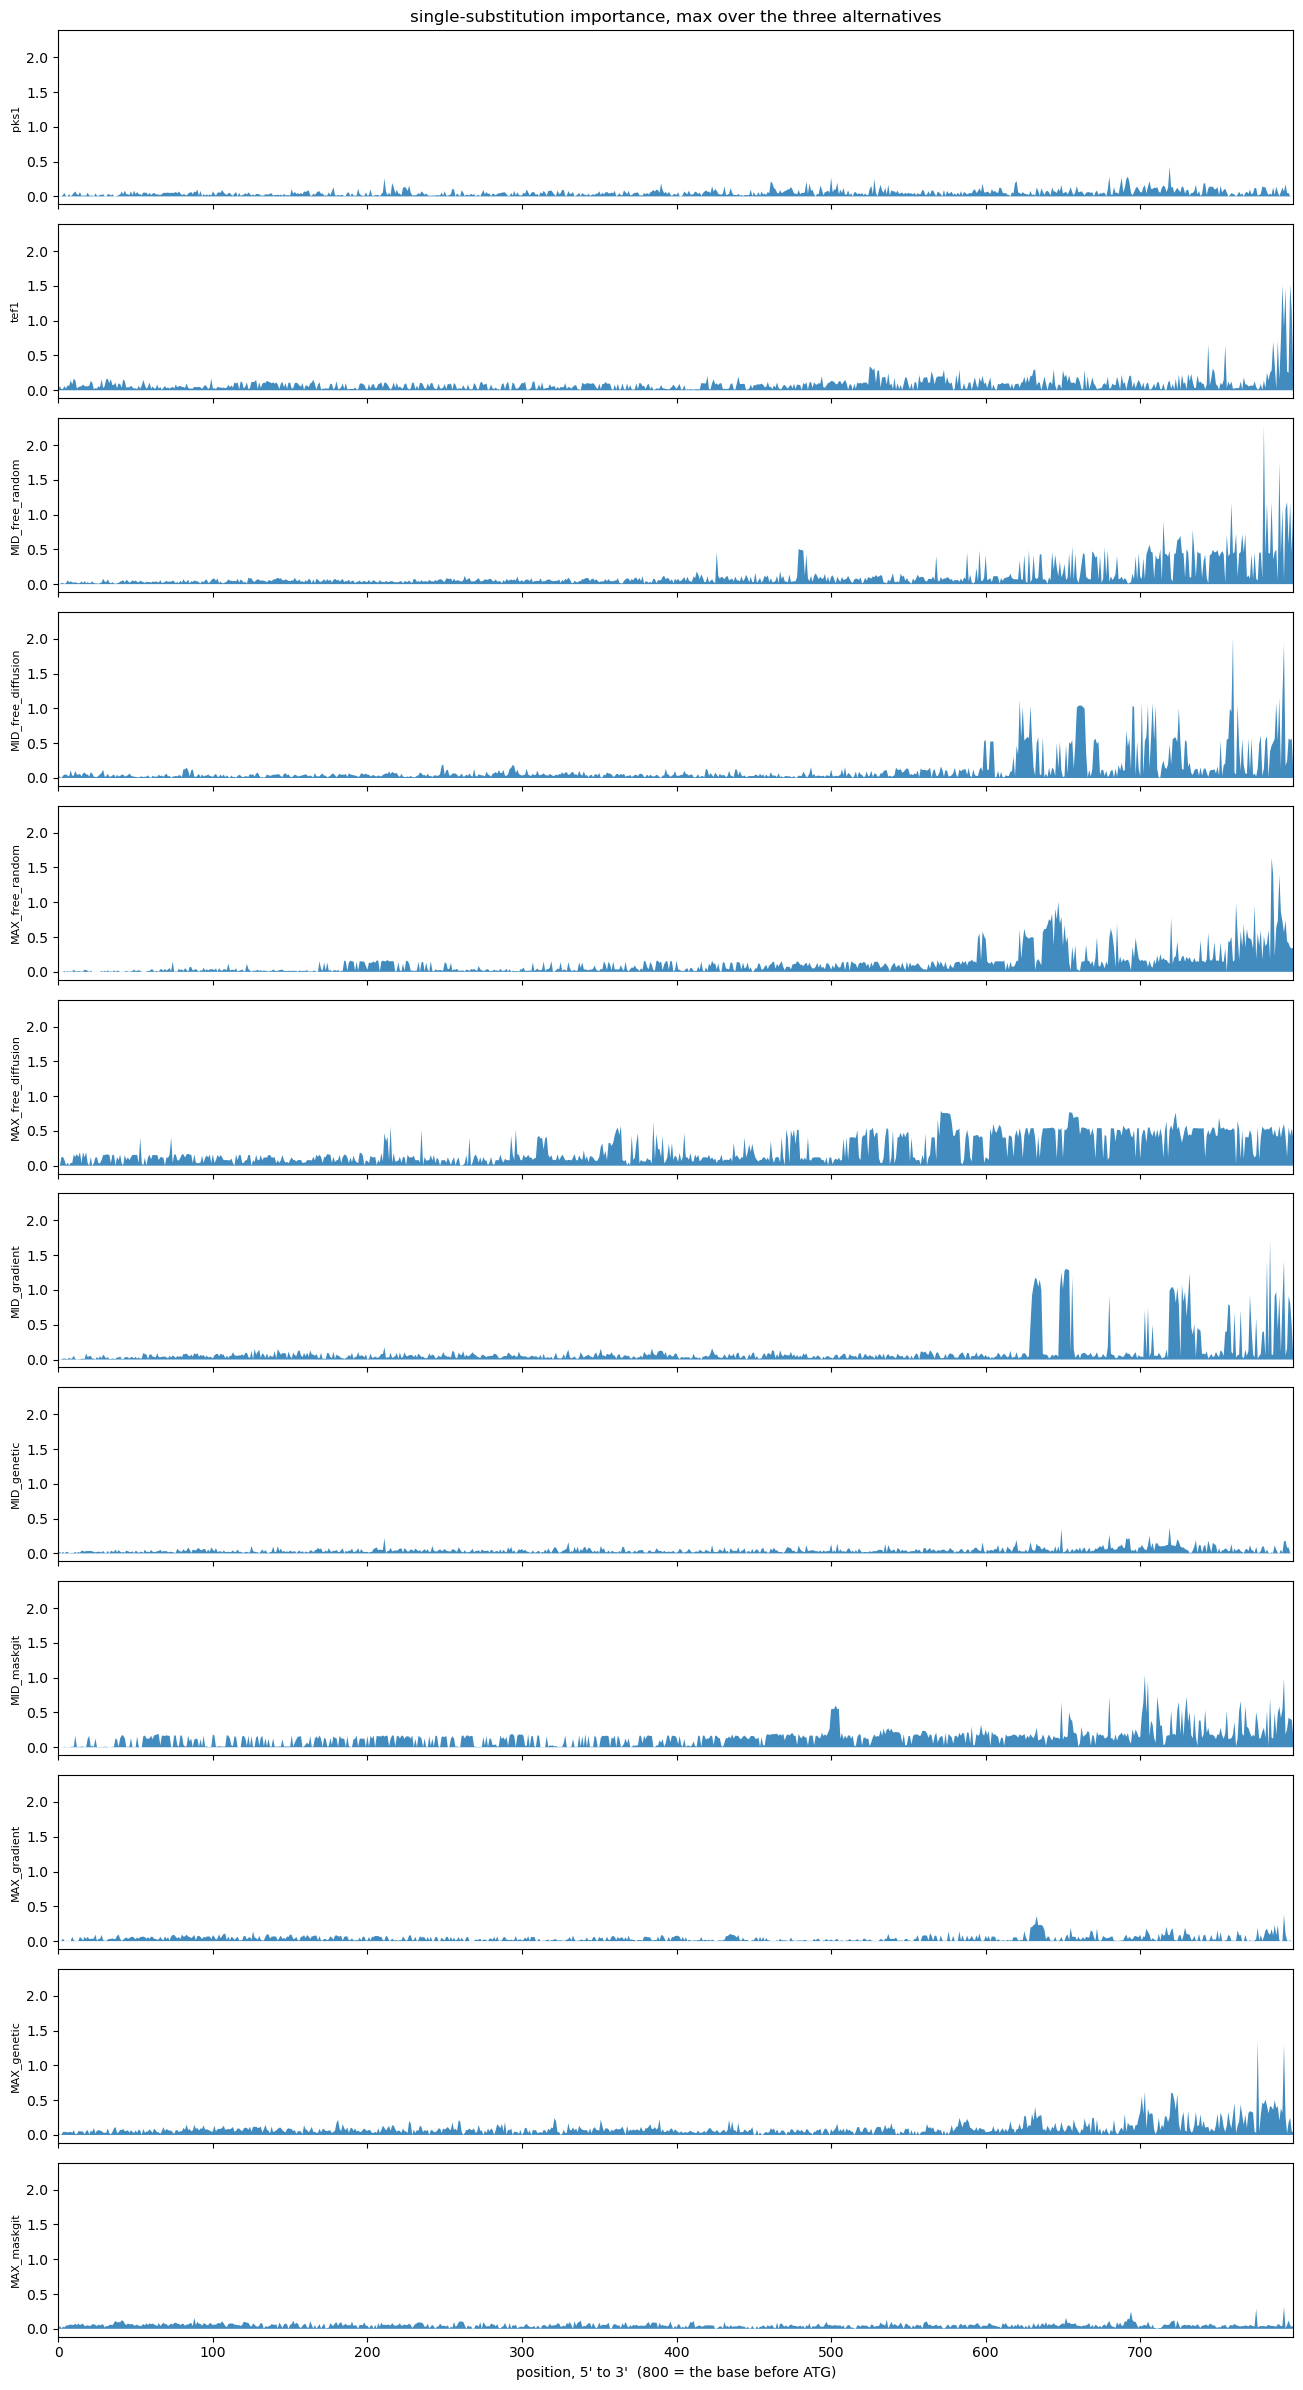

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(len(TARGETS), 1, figsize=(13, 2.0 * len(TARGETS)),
                         sharex=True, sharey=True)
for ax, n in zip(np.atleast_1d(axes), TARGETS):
    imp = np.abs(ISM[n]).max(axis=1)
    ax.fill_between(np.arange(800), imp, lw=0, alpha=0.85)
    ax.set_ylabel(n.replace("pks1_syn_", ""), fontsize=8)
    ax.margins(x=0)
np.atleast_1d(axes)[-1].set_xlabel("position, 5' to 3'  (800 = the base before ATG)")
np.atleast_1d(axes)[0].set_title("single-substitution importance, max over the three alternatives")
plt.tight_layout(); plt.show()


**How to read this.** A tall spike is a position where one substitution moves
the prediction a long way; a flat stretch is sequence the model is indifferent
to. Importance concentrated near the 3' end would mean the model has learned
proximity to the start codon; discrete narrow peaks would suggest motifs.
`pks1` and `tef1` are different promoters and should not share a shape.

## 4. Per-level ablation: which length scale carries the prediction

The latent is a ladder of five levels, each tiling the same 800 bp at a
different resolution, so silencing one level asks about a **length scale**, which is
the property that makes this latent auditable rather than merely accurate.

A level is silenced by replacing its codes with the grid's zero cell, the
"no refinement" symbol every refinement level carries by construction, and
which is what makes a truncated ladder a legal code at all.

In [7]:
@torch.no_grad()
def level_ablation(seq):
    x = one_hot([seq]).to(DEVICE)
    sp = torch.full((1,), P1, dtype=torch.long, device=DEVICE)
    idx = model.encode_codes(x)
    base = model.predykcja_z_kodow(idx) if hasattr(model, "predykcja_z_kodow") else None
    ref = predict([seq])[0]
    rows = []
    for lv in range(len(idx)):
        hacked = [t.clone() for t in idx]
        q = model.ladder.tangent_quantizers[lv - 1] if lv > 0 else None
        zero = int(q.zero_index()) if q is not None and hasattr(q, "zero_index") else 0
        hacked[lv] = torch.full_like(hacked[lv], zero)
        logits = model.decode_codes(hacked)
        seq2 = "".join(BASES[c] for c in logits.argmax(1)[0].cpu().numpy())
        changed = sum(1 for a, b in zip(seq, seq2) if a != b)
        rows.append((lv, predict([seq2])[0] - ref, changed))
    return ref, rows

ref, rows = level_ablation(PKS1)
print("pks1, reference %+.4f" % ref)
print("%-6s %12s %16s" % ("level", "delta mu", "bases changed"))
for lv, d, ch in rows:
    print("L%-5d %+12.4f %16d" % (lv, d, ch))


pks1, reference +0.7175
level      delta mu    bases changed
L0          +0.1018                3
L1          +0.0012                1
L2          +1.1688              190
L3          +1.7721              171
L4          -0.2159              340


**The asymmetry here is a known, load-bearing property.** The coarse level
moves the prediction a great deal while changing almost no bases; the fine
levels rewrite hundreds of bases and barely move it. That is why the design
pipeline scores candidates by **decoding them to DNA**, never in code space -
a sampler guided by a code-space score would optimise a number the acceptance
gate never sees. The opposite pattern in the table above would mean this is
not the checkpoint the panel was built from.

## 5. Motif occupancy: what the designs gained and lost

The encoder's first layer includes the occupancy of 252 frozen PWM profiles,
scanned on both strands. Comparing a design's occupancy with `pks1`'s says
which binding-site-like features the edits created or destroyed, in the
vocabulary of the motif library rather than in the model's own latent.

In [8]:
@torch.no_grad()
def occupancy(seq):
    x = one_hot([seq]).to(DEVICE)
    occ = model.occupancy(x) if hasattr(model, "occupancy") else None
    if occ is None:
        raise RuntimeError("this checkpoint exposes no motif bank")
    return occ[0].float().cpu().numpy()          # [motifs, positions]

names_m = getattr(getattr(model, "occupancy", None), "names", None)
base_occ = occupancy(PKS1).max(axis=1)
print("motif channels:", base_occ.shape[0])

rows = []
for n in [x for x in names if x.startswith("pks1_syn")]:
    d = occupancy(SEQS[n]).max(axis=1) - base_occ
    k = int(np.abs(d).argmax())
    rows.append((n, float(d[k]), k, float(np.abs(d).sum())))
print()
print("%-28s %10s %8s %12s" % ("design", "max shift", "channel", "total |shift|"))
for n, v, k, tot in sorted(rows, key=lambda r: -abs(r[1])):
    label = names_m[k] if names_m and k < len(names_m) else "#%d" % k
    print("%-28s %+10.4f %8s %12.3f" % (n, v, label, tot))


motif channels: 284

design                        max shift  channel total |shift|
pks1_syn_MID_free_diffusion     +2.1249      #30       92.004
pks1_syn_MID_free_random        +1.9710     #209       79.995
pks1_syn_MAX_free_random        -1.5825     #251       82.506
pks1_syn_MAX_free_diffusion     -1.5083     #220       98.529
pks1_syn_MAX_gradient           +1.4762      #72       31.494
pks1_syn_MAX_maskgit            +1.4459      #72       41.664
pks1_syn_MID_gradient           +1.3551      #72       12.248
pks1_syn_MAX_genetic            +1.2440     #242       49.252
pks1_syn_MID_maskgit            +1.1631      #72       21.516
pks1_syn_MID_genetic            -1.0024     #200        5.774


## 6. Which motifs the model treats as important

Section 5 asked which motifs a design *contains*; this asks which it *uses*.
A site can be present and ignored, or absent and sorely missed.

Occupancy is an **input**, so the question is answered by intervening on it,
not by reading weights off the bank. Two interventions separate two claims:
**zeroing** removes the motif entirely, and **shuffling** it along the
sequence keeps *how much* while destroying *where*. A channel that matters
only when zeroed is used as a count; one that also matters when shuffled is
used positionally.

The bank's halves answer to different authorities and are reported separately:
252 **frozen** profiles from a curated library, carrying real
transcription-factor names, and 32 **de novo** filters the model learned
itself, which have no names and are summarised by their consensus.

First a positive control: passing the model its own occupancy must reproduce
the default prediction **exactly**. If it does not, the injection is not wired
and everything below measures nothing - this repository has shipped a flag
that did precisely that.

In [9]:
occ_mod = model.occupancy
N_FROZEN = len(occ_mod.frozen.names)
N_DENOVO = occ_mod.de_novo.logits.shape[0] if occ_mod.de_novo is not None else 0
print("occupancy channels: %d frozen + %d de novo" % (N_FROZEN, N_DENOVO))

def denovo_consensus(i, min_bits=0.30):
    # Read a learned filter the way one reads a PWM: softmax over bases,
    # then keep only the positions that actually carry information. A
    # filter whose every column is near-uniform has no consensus, and
    # printing one for it would invent a motif that is not there.
    w = occ_mod.de_novo.logits[i].detach().float()
    p = torch.softmax(w, dim=0).cpu().numpy()
    out = []
    for j in range(p.shape[1]):
        col = p[:, j]
        bits = 2.0 + float((col * np.log2(np.clip(col, 1e-9, None))).sum())
        out.append(BASES[int(col.argmax())] if bits >= min_bits else ".")
    return "".join(out).strip(".") or "(no consensus)"

LABELS = list(occ_mod.frozen.names) + [
    "denovo%02d %s" % (i, denovo_consensus(i)) for i in range(N_DENOVO)]
BANK = ["frozen"] * N_FROZEN + ["de novo"] * N_DENOVO
print("example frozen  :", LABELS[:3])
print("example de novo :", LABELS[N_FROZEN:N_FROZEN + 3])


occupancy channels: 252 frozen + 32 de novo
example frozen  : ['pp-1', 'RO3G_05801', 'FGRRES_17238']
example de novo : ['denovo00 ACGTGGGG', 'denovo01 CACC.TCT.T', 'denovo02 TTT...CGG']


In [10]:
@torch.no_grad()
def predict_with_occ(seqs, occ=None, batch=16):
    out = []
    for s in range(0, len(seqs), batch):
        chunk = seqs[s:s + batch]
        x = one_hot(chunk).to(DEVICE)
        sp = torch.full((len(chunk),), P1, dtype=torch.long, device=DEVICE)
        o = occ[s:s + batch] if occ is not None else None
        r = model(x, occupancy=o, species_id=sp, reconstruct=False)
        mu = r["absolute"].mu
        out.append((mu.mean(-1) if mu.dim() > 1 else mu).float().cpu().numpy())
    return np.concatenate(out)

PANEL_SEQS = [SEQS[n] for n in names]
with torch.no_grad():
    OCC = torch.cat([model.occupancy(one_hot(PANEL_SEQS[i:i + 16]).to(DEVICE))
                     for i in range(0, len(PANEL_SEQS), 16)])

ref_default = predict_with_occ(PANEL_SEQS)
ref_injected = predict_with_occ(PANEL_SEQS, OCC)
gap = float(np.abs(ref_default - ref_injected).max())
print("POSITIVE CONTROL  max|default - injected| = %.3e" % gap)
assert gap < 1e-4, (
    "the model is not using the occupancy it was handed; every importance "
    "below would be measuring nothing")
print("occupancy tensor:", tuple(OCC.shape))


POSITIVE CONTROL  max|default - injected| = 0.000e+00
occupancy tensor: (12, 284, 800)


In [11]:
rng = np.random.default_rng(7898)

def ablate(channel, mode):
    occ = OCC.clone()
    if mode == "zero":
        occ[:, channel, :] = 0.0
    else:                                   # keep how much, destroy where
        perm = torch.from_numpy(
            rng.permutation(occ.shape[2])).to(occ.device)
        occ[:, channel, :] = occ[:, channel, perm]
    return predict_with_occ(PANEL_SEQS, occ)

imp_zero = np.zeros(OCC.shape[1])
imp_shuf = np.zeros(OCC.shape[1])
for c in range(OCC.shape[1]):
    imp_zero[c] = np.abs(ablate(c, "zero") - ref_injected).mean()
    imp_shuf[c] = np.abs(ablate(c, "shuffle") - ref_injected).mean()
    if c % 60 == 0:
        print("  %d / %d channels" % (c, OCC.shape[1]))
print("done")


  0 / 284 channels


  60 / 284 channels


  120 / 284 channels


  180 / 284 channels


  240 / 284 channels


done


In [12]:
order = np.argsort(-imp_zero)
print("%-34s %-8s %10s %10s" % ("motif", "bank", "zeroed", "shuffled"))
print("-" * 66)
for c in order[:20]:
    print("%-34s %-8s %10.5f %10.5f"
          % (LABELS[c][:34], BANK[c], imp_zero[c], imp_shuf[c]))

for bank in ("frozen", "de novo"):
    idx = [c for c in order if BANK[c] == bank][:8]
    tot = imp_zero[[c for c in range(len(BANK)) if BANK[c] == bank]].sum()
    print()
    print("top of the %s bank (bank total %.4f)" % (bank, tot))
    for c in idx:
        print("   %-40s %.5f" % (LABELS[c][:40], imp_zero[c]))


motif                              bank         zeroed   shuffled
------------------------------------------------------------------
NCU01994                           frozen      0.17834    0.19021
denovo01 CACC.TCT.T                de novo     0.16692    0.17246
NCU01074                           frozen      0.16177    0.07557
ANIA_04606                         frozen      0.14912    0.16313
cpc-1                              frozen      0.13672    0.17314
NCU08159                           frozen      0.13570    0.09398
NCU06399                           frozen      0.11722    0.11538
ANIA_00033                         frozen      0.11449    0.08657
NCU04848                           frozen      0.11159    0.10671
denovo02 TTT...CGG                 de novo     0.11035    0.06963
DAL81                              frozen      0.11033    0.11366
denovo27 AT.GCGG                   de novo     0.10937    0.09182
denovo13 A.GGGAGCTCA               de novo     0.10577    0.10712
NCU00223 

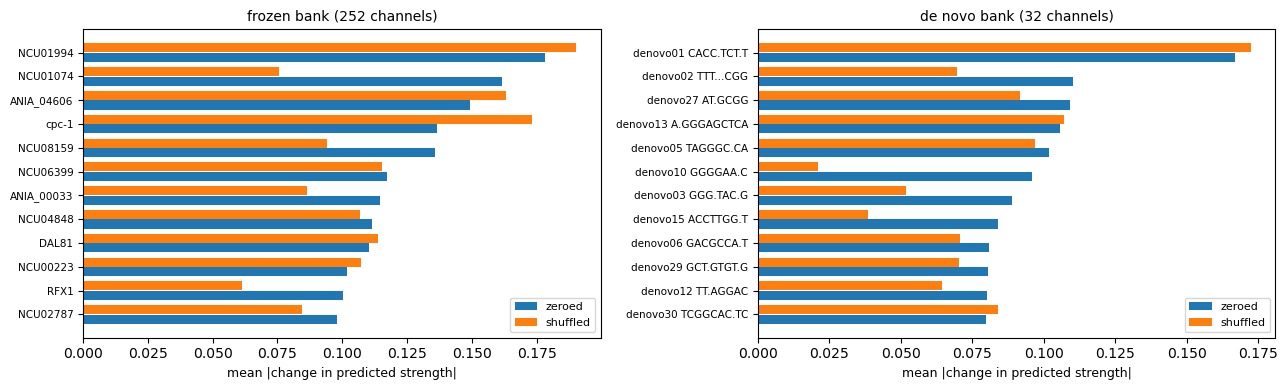

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, bank in enumerate(("frozen", "de novo")):
    sel = [c for c in range(len(BANK)) if BANK[c] == bank]
    top = sorted(sel, key=lambda c: -imp_zero[c])[:12][::-1]
    y = np.arange(len(top))
    ax[k].barh(y - 0.2, [imp_zero[c] for c in top], height=0.38, label="zeroed")
    ax[k].barh(y + 0.2, [imp_shuf[c] for c in top], height=0.38, label="shuffled")
    ax[k].set_yticks(y)
    ax[k].set_yticklabels([LABELS[c][:30] for c in top], fontsize=7.5)
    ax[k].set_title("%s bank (%d channels)" % (bank, len(sel)), fontsize=10)
    ax[k].set_xlabel("mean |change in predicted strength|", fontsize=9)
    ax[k].legend(fontsize=8)
plt.tight_layout(); plt.show()


**How to read the two bars.** A tall *zeroed* bar with a short *shuffled* one
means the model counts that motif and ignores where it sits. Two tall bars
mean position matters too. Two short bars mean the channel is not reached -
and with 284 channels most will be, which is itself worth seeing: the bank is
far larger than the part the model leans on.

**What this is not.** It is an intervention on the model's input, not a claim
about biology. A frozen profile scoring highly means *this model* uses that
channel on *these twelve sequences*, not that the factor binds. The de novo
filters carry no external authority at all; their consensus is read off the
learned weights, and a filter with near-uniform columns is reported as having
none rather than given an invented one.

### 6b. Are these motifs real, and are they promoter motifs?

The ranking above answers neither question.

The first is whether a channel the model leans on actually **occurs** here. A
channel can score highly under occlusion while never firing, in which case the
effect belongs to the network rather than to any site in the DNA. The
occupancy tensor already answers it.

The second is whether the bank is a promoter bank at all. The 252 frozen
profiles are experimentally derived fungal binding profiles whose names follow
*Neurospora* nomenclature, not the *Trichoderma* names a reader expects:
carbon catabolite repression is `cre-1`, not `CRE1`; the xylanase regulator is
`xlr-1`, not `XYR1`; the blue-light receptors are `wc-1` and `wc-2`, not
`BLR1` and `BLR2`. Searching for the *Trichoderma* spellings returns nothing
and would wrongly read as "the regulators are missing".

In [14]:
# Does a channel the model leans on actually fire in these sequences?
peak = OCC[:, :N_FROZEN, :].amax(dim=2).amax(dim=0).float().cpu().numpy()
silent = int((peak < 0.05).sum())
print("frozen channels that never fire in the panel : %d of %d"
      % (silent, N_FROZEN))
print("lowest peak occupancy of any frozen channel  : %.3f" % peak.min())
print()
print("%-22s %6s %10s %10s" % ("motif", "rank", "zeroed", "peak occ"))
print("-" * 52)
frozen_order = [c for c in order if BANK[c] == "frozen"]
for r, c in enumerate(frozen_order[:15], start=1):
    print("%-22s %6d %10.5f %10.3f"
          % (LABELS[c][:22], r, imp_zero[c], peak[c]))

# The spread matters more than the ordering. If the top channel is only a
# little above the median one, no motif is carrying the prediction.
z = imp_zero[[c for c in range(len(BANK)) if BANK[c] == "frozen"]]
print()
print("frozen bank: max %.4f | median %.4f | ratio %.2f"
      % (z.max(), np.median(z), z.max() / np.median(z)))

frozen channels that never fire in the panel : 0 of 252
lowest peak occupancy of any frozen channel  : 1.885

motif                    rank     zeroed   peak occ
----------------------------------------------------
NCU01994                    1    0.17834      3.461
NCU01074                    2    0.16177      4.110
ANIA_04606                  3    0.14912      3.586
cpc-1                       4    0.13672      2.350
NCU08159                    5    0.13570      3.624
NCU06399                    6    0.11722      3.796
ANIA_00033                  7    0.11449      3.325
NCU04848                    8    0.11159      3.879
DAL81                       9    0.11033      4.738
NCU00223                   10    0.10185      4.029
RFX1                       11    0.10047      3.775
NCU02787                   12    0.09786      2.855
SFP1                       13    0.09290      4.195
LYS14                      14    0.09184      2.838
NCU08055                   15    0.08952      3.591

froz

In [15]:
# Where do the canonical regulators of fungal promoters sit in that
# ranking? The roles are annotation, not measurement, so they are written
# out in full rather than implied by a name the reader may not know.
ROLES = [
    ("cpc-1",  "amino-acid starvation (GCN4 orthologue)"),
    ("clr-2",  "cellulose degradation"),
    ("cre-1",  "carbon catabolite repression (CRE1 orthologue)"),
    ("nuc-1",  "phosphate starvation (PHO4 orthologue)"),
    ("nirA",   "nitrate regulation"),
    ("csp-1",  "circadian clock output"),
    ("nit-4",  "nitrate regulation"),
    ("wc-1",   "blue-light receptor (BLR1 orthologue)"),
    ("xlr-1",  "xylanase induction (XYR1 orthologue)"),
    ("sub-1",  "development"),
    ("qa-1F",  "quinic acid pathway"),
    ("hsf-1",  "heat shock"),
    ("wc-2",   "blue-light receptor (BLR2 orthologue)"),
    ("msn-1",  "general stress response"),
    ("STE12",  "pheromone response and invasive growth"),
    ("nit-2",  "nitrogen regulation (AREA orthologue)"),
    ("sre",    "iron uptake"),
]
rank_of = {LABELS[c]: r for r, c in enumerate(frozen_order, start=1)}
imp_of = {LABELS[c]: imp_zero[c] for c in frozen_order}
peak_of = {LABELS[c]: peak[c] for c in frozen_order}

print("%-10s %6s %10s %10s  %s"
      % ("motif", "rank", "zeroed", "peak occ", "role"))
print("-" * 78)
found = 0
for m, role in ROLES:
    if m in rank_of:
        found += 1
        print("%-10s %6d %10.5f %10.3f  %s"
              % (m, rank_of[m], imp_of[m], peak_of[m], role))
    else:
        print("%-10s %6s %10s %10s  %s" % (m, "absent", "-", "-", role))
print()
print("canonical regulators present in the bank: %d of %d"
      % (found, len(ROLES)))

motif        rank     zeroed   peak occ  role
------------------------------------------------------------------------------
cpc-1           4    0.13672      2.350  amino-acid starvation (GCN4 orthologue)
clr-2          42    0.07353      3.371  cellulose degradation
cre-1          55    0.06969      3.198  carbon catabolite repression (CRE1 orthologue)
nuc-1          78    0.06456      4.482  phosphate starvation (PHO4 orthologue)
nirA           72    0.06562      3.252  nitrate regulation
csp-1         100    0.05914      3.303  circadian clock output
nit-4         108    0.05698      4.016  nitrate regulation
wc-1          118    0.05449      4.013  blue-light receptor (BLR1 orthologue)
xlr-1         110    0.05666      2.389  xylanase induction (XYR1 orthologue)
sub-1         117    0.05467      3.971  development
qa-1F         126    0.05263      3.545  quinic acid pathway
hsf-1         144    0.04715      2.861  heat shock
wc-2          158    0.04450      2.444  blue-light rece

**What 6b settles, and what it refuses to settle.**

Every frozen channel fires somewhere in this panel, so nothing in the ranking
scores while absent, and the canonical regulators are present under their
*Neurospora* names.

That is not learned regulation. The strongest frozen channel moves the
prediction about three times as much as the median, on a panel spanning more
than nine units with no motif carries the result. Most of the strongest channels
are uncharacterised *Neurospora* and *Aspergillus* identifiers, and a profile
is evidence about binding measured in another species, not about a site bound
in *T. atroviride*. The model spreads its dependence thinly across a
pan-fungal bank, with the named regulators present but not dominant.

## 7. Do the edits land where the model looks?

The surgical designs changed a handful of bases. If the design pipeline and
the explanation agree, those positions should sit on the high-importance part
of `pks1`'s own profile rather than at random.

A failure here would be informative: it would mean the search found its gain
somewhere the single-substitution scan cannot see, which is possible, because
a set of edits can interact while each alone does nothing.

In [16]:
imp_pks1 = np.abs(ISM["pks1"]).max(axis=1)
order = np.argsort(np.argsort(imp_pks1)) / (len(imp_pks1) - 1.0)   # 0..1 percentile

print("%-28s %6s %18s %16s" % ("design", "edits", "median importance pct", "expected 0.50"))
for n in [x for x in names if x.startswith("pks1_syn")]:
    pos = [i for i, (a, b) in enumerate(zip(PKS1, SEQS[n])) if a != b]
    if not pos or len(pos) > 100:          # free-regime arms are not edits
        continue
    pct = float(np.median(order[pos]))
    print("%-28s %6d %18.3f %16s" % (n, len(pos), pct,
                                     "above" if pct > 0.5 else "below"))


design                        edits median importance pct    expected 0.50
pks1_syn_MID_gradient            16              0.879            above
pks1_syn_MID_genetic              5              0.599            above
pks1_syn_MID_maskgit             16              0.950            above
pks1_syn_MAX_gradient            59              0.857            above
pks1_syn_MAX_genetic             63              0.778            above
pks1_syn_MAX_maskgit             63              0.827            above


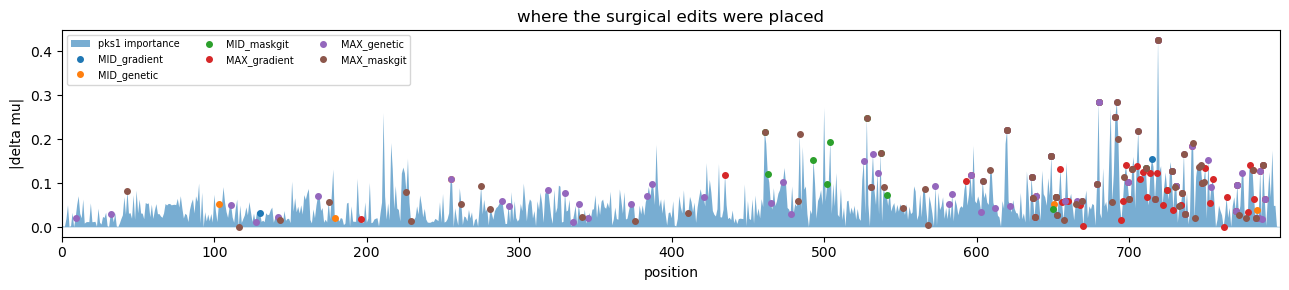

In [17]:
fig, ax = plt.subplots(figsize=(13, 3))
ax.fill_between(np.arange(800), imp_pks1, lw=0, alpha=0.6, label="pks1 importance")
for n in [x for x in names if x.startswith("pks1_syn")]:
    pos = [i for i, (a, b) in enumerate(zip(PKS1, SEQS[n])) if a != b]
    if pos and len(pos) <= 100:
        ax.plot(pos, [imp_pks1[p] for p in pos], "o", ms=4, label=n.replace("pks1_syn_", ""))
ax.set_xlabel("position"); ax.set_ylabel("|delta mu|"); ax.margins(x=0)
ax.legend(fontsize=7, ncol=3); ax.set_title("where the surgical edits were placed")
plt.tight_layout(); plt.show()


## 8. The gene this project is about

Everything above treats the twelve sequences as interchangeable rows. This
section asks what is known about **pks1**, what that predicts about its
promoter, and whether the model agrees.

`pks1` encodes an iterative type I polyketide synthase and is required to make
**6-pentyl-α-pyrone (6-PP)**, the coconut-smelling volatile that is this
species' signature metabolite and much of why it is used for biocontrol. Three
independent deletion mutants lose 6-PP completely and much of their antifungal
activity against *Botrytis cinerea* and *Rhizoctonia solani*. That work was
done in strain **P1**, the strain this model is conditioned on.

Two consequences pull in opposite directions. **pks1 is a sensible design
target** - a real, strong, single-gene switch on a metabolite the team cares
about. And **its regulation is light-dependent**, which is falsifiable: 6-PP
output is highest in darkness, and a Δ*blr1* mutant makes more in both light
and dark, placing BLR1 upstream as a repressor. If that repression is
transcriptional and direct, the promoter should carry light response elements.

One caveat before the result rather than after it: **no promoter or
cis-element analysis of pks1 has been published, in any *Trichoderma***. The
consensuses below come from promoters where they were mapped; chiefly
*phr-1*, where BLR-2 binding was shown by ChIP. This is a prediction about
pks1, not a check against a known answer.

### 8a. The sites we look for, and how good the evidence for each one is

A motif list is only as good as its provenance, so each row carries a tier.
Tier 1 means binding or footprinting shown in *Trichoderma* itself; tier 2, a
consensus established in *Trichoderma* but at unrelated target genes; tier 3,
carried over from *Neurospora* or *Aspergillus*. Mixing tiers silently is how
a scan ends up reporting a *Neurospora* consensus as local knowledge.

The light elements are the rows this promoter is predicted to carry. The rest
are the standard repertoire with carbon catabolite repression, the CCAAT complex,
the xylanase activator and we expect nothing from them, which is why they
are useful: a scan where everything scores has a broken null.

In [18]:
import sys

sys.path.insert(0, os.path.join(REPO, "scripts"))
from pks1_motifs import MOTIFS, attention_at, dinuc_shuffle, find_all

print("%-7s %-10s %-5s %-22s %s"
      % ("key", "consensus", "tier", "regulator", "what it is"))
print("-" * 100)
for key, cons, reg, what, tier in MOTIFS:
    print("%-7s %-10s %-5d %-22s %s" % (key, cons, tier, reg, what))

key     consensus  tier  regulator              what it is
----------------------------------------------------------------------------------------------------
CRE1    SYGGRG     1     CRE1 / CreA            carbon catabolite repression; functional sites are usually CLOSE PAIRS
CCAAT   CCAAT      1     Hap2/3/5 complex       general promoter element, constitutively bound in T. reesei
XYR1    GGCTAA     2     XYR1                   cellulase/xylanase activator; no published reason to sit at a PKS
XYR1w   GGCWWW     2     XYR1, relaxed          the GGC(A/T)3 variant from the same work
LRE     CGATB      1     BLR1/BLR2 complex      light element; the mapped region held FIVE copies in ~50 bp
WCC     GATCGA     3     white-collar complex   Neurospora WCC consensus; NOT shown in Trichoderma
GATC    GATC       3     GATA-type repeat core  the repeat unit of Neurospora light-response elements


### 8b. Are the sites there at all?

Counting matches is not enough: a 5-letter word turns up in any 800-letter
string by chance, at a rate that depends on composition, and GC-rich DNA
produces GC-rich motifs for free.

The null therefore preserves composition exactly of 2000 shuffles of pks1 that
keep every **dinucleotide** frequency, holding base composition and local
stacking fixed while destroying only arrangement. A motif has to beat its own
sequence, reshuffled.

In [19]:
rng_m = np.random.default_rng(7898)
nulls = [dinuc_shuffle(PKS1, rng_m) for _ in range(2000)]
assert all(sorted(s) == sorted(PKS1) for s in nulls[:5]), \
    "the shuffle changed base composition; the null would be the wrong null"

MOT = {}
print("%-7s %-10s %5s %8s %7s %8s  %s"
      % ("key", "consensus", "n", "null", "z", "p", "tier"))
print("-" * 68)
for key, cons, reg, what, tier in MOTIFS:
    pos = find_all(PKS1, cons)
    nd = np.array([len(find_all(s, cons)) for s in nulls], dtype=float)
    mu, sd = nd.mean(), nd.std()
    z = (len(pos) - mu) / sd if sd > 0 else 0.0
    p = (int((nd >= len(pos)).sum()) + 1) / (len(nd) + 1)
    MOT[key] = {"pos": pos, "cons": cons, "z": z, "p": p, "tier": tier}
    print("%-7s %-10s %5d %8.1f %7.2f %8.4f  %d"
          % (key, cons, len(pos), mu, z, p, tier))

key     consensus      n     null       z        p  tier
--------------------------------------------------------------------
CRE1    SYGGRG         2      2.4   -0.28   0.7136  1
CCAAT   CCAAT          0      1.8   -1.38   1.0000  1


XYR1    GGCTAA         0      0.4   -0.63   1.0000  2
XYR1w   GGCWWW         3      3.4   -0.23   0.6782  2
LRE     CGATB          7      4.9    0.97   0.2189  1
WCC     GATCGA         1      0.4    0.93   0.3133  3


GATC    GATC           4      3.3    0.43   0.4298  3


**Nothing is enriched, including the elements the biology predicts.**

Every row sits within about one standard deviation of its own null. The carbon
catabolite repression site, the CCAAT box and the xylanase activator are at or
below chance, and two do not occur here at all. The light element is the
highest row of seven occurrences against a null of 4.9 and still does not
clear it, at about one standard deviation and an empirical p of 0.22.

What this rules out is narrow. It does not say pks1 is not light-regulated:
those measurements are solid, and regulation can be indirect, run through
chromatin, or work through sites matching no consensus derived from another
promoter. It says that **the 800 bases immediately upstream of pks1 carry no
excess of any canonical site we know how to write down**, so there is no
obvious motif for a design method to add or remove.

**On provenance.** The light element consensus is `CGATB`, read from the
published *phr-1* abstract (five CGATB motifs in a ~50 bp window, three in
opposite polarity to canonical WCC sites). A secondary summary renders it
`GATCB`; scanning with that moves the row, because a string nobody published
will score like one. The conclusion is unchanged either way.

### 8c. Does the model look where the literature points?

A site can be present and ignored. The question this notebook can answer is
about the *model*, not the DNA: are the positions covered by these motifs
positions whose mutation moves the prediction?

Two things make that harder than it sounds, and both are handled below.
Importance is not uniform but it rises towards the start codon, so a uniform
null would reward any motif sitting at the 3' end whatever it is. And
importance is autocorrelated, so scattered single positions are easier to beat
than the same number packed into blocks. The null therefore draws **the same
number of blocks, of the same width**, at random positions.

The positive control is load-bearing: the most important 5 % of positions must
beat this null decisively. If they do not, the null is too hard and every
negative row below means nothing.

In [20]:
imp_p = np.abs(ISM["pks1"]).max(axis=1)      # [800], from section 3

k_top = max(1, len(imp_p) // 20)
top_pos = [int(i) for i in np.argsort(-imp_p)[:k_top]]
ctrl = attention_at(imp_p, top_pos, 1, np.random.default_rng(7898))

print("%-8s %9s %9s %7s %8s" % ("", "observed", "null", "z", "p"))
print("-" * 46)
print("%-8s %9.5f %9.5f %7.2f %8.4f   <- positive control"
      % ("top 5%", ctrl["observed"], ctrl["null_mean"], ctrl["z"],
         ctrl["p_empirical"]))
assert ctrl["p_empirical"] <= 0.01, (
    "the most important 5%% of positions do not beat the matched null "
    "(p=%.4f), so this null cannot detect anything and the rows below it "
    "would be meaningless." % ctrl["p_empirical"])

for key, cons, reg, what, tier in MOTIFS:
    a = attention_at(imp_p, MOT[key]["pos"], len(cons),
                     np.random.default_rng(7899))
    MOT[key]["att"] = a
    if a is None:
        print("%-8s %9s %9s %7s %8s   (no sites)" % (key, "-", "-", "-", "-"))
    else:
        print("%-8s %9.5f %9.5f %7.2f %8.4f"
              % (key, a["observed"], a["null_mean"], a["z"],
                 a["p_empirical"]))

          observed      null       z        p
----------------------------------------------
top 5%     0.19611   0.05421   19.26   0.0001   <- positive control
CRE1       0.07017   0.05471    0.75   0.2040
CCAAT            -         -       -        -   (no sites)
XYR1             -         -       -        -   (no sites)


XYR1w      0.03883   0.05459   -0.94   0.8271
LRE        0.05415   0.05467   -0.05   0.4849


WCC        0.03591   0.05484   -0.64   0.7164
GATC       0.07023   0.05448    1.00   0.1577


**The control fires and the motifs do not.** The top 5 % of positions beat
their matched null by about nineteen standard deviations, so the instrument
works. Against that, no motif row clears one standard deviation.

With 8b this says something cleaner than either alone: the sites are not there
in excess, **and** the model is not using the ones that are. The model is not
doing hidden motif biology on this promoter. The next section asks what it is
doing instead.

## 9. What the model weighs instead

The positive control above is also a finding: the most important 5 % of
positions move the prediction about 3.6 times as much as the average one, so
sensitivity is not spread evenly. There is structure to find — just not the
structure we went looking for.

Two patterns come out of it, and the second was a surprise.

In [21]:
L = len(imp_p)
print("importance by 80 bp bin, counted back from the base before the ATG\n")
for b in range(10):
    s, e = b * 80, (b + 1) * 80
    bar = "#" * int(round(imp_p[s:e].mean() / imp_p.max() * 46))
    print("  -%4d..-%4d  %.4f  %s" % (L - s, L - e + 1, imp_p[s:e].mean(), bar))

from scipy.stats import spearmanr

rho, pv = spearmanr(imp_p, np.arange(L)[::-1] + 1)
print("\nSpearman of importance against distance from the start codon: "
      "%+.4f (p %.1e)" % (rho, pv))
print("negative means the model weighs the proximal promoter more")

importance by 80 bp bin, counted back from the base before the ATG

  - 800..- 721  0.0317  ###
  - 720..- 641  0.0348  ####
  - 640..- 561  0.0469  #####
  - 560..- 481  0.0366  ####
  - 480..- 401  0.0445  #####
  - 400..- 321  0.0554  ######
  - 320..- 241  0.0676  #######
  - 240..- 161  0.0584  ######
  - 160..-  81  0.0936  ##########
  -  80..-   1  0.0726  ########



Spearman of importance against distance from the start codon: -0.3562 (p 2.4e-25)
negative means the model weighs the proximal promoter more


The first is a **positional prior**: importance climbs steadily towards the
start codon, roughly tripling from the far end of the window to the last 160
bases. Nobody put it there. The model has no coordinate input beyond a single
parameter-free ramp and was never told that proximal promoter sequence matters
more. It is what one would want a promoter model to learn.

The second pattern is what sits at the top of the ranking.

In [22]:
def occ(s, pat):
    return [i for i in range(len(s) - len(pat) + 1) if s[i:i+len(pat)] == pat]

# The null is drawn from each site's OWN +/-50 bp neighbourhood, so the
# positional trend above is held fixed and only the word differs. Drawing it
# uniformly would hand any 3' word a free advantage.
W = 50
_cs = np.concatenate([[0.0], np.cumsum(imp_p)])      # prefix sums

def local_null(positions, w=3, draws=20000, seed=11):
    """Vectorised: every draw replaces each site with another window from
    that site's own neighbourhood, so distance from the start codon is held
    fixed across the null and only the word changes."""
    rng = np.random.default_rng(seed)
    pos = np.asarray(positions)
    obs = float(np.mean((_cs[pos + w] - _cs[pos]) / w))
    lo = np.maximum(0, pos - W)
    hi = np.minimum(L - w, pos + W)
    q = (lo + rng.random((draws, len(pos))) * (hi - lo + 1)).astype(int)
    q = np.clip(q, lo, hi)
    nl = ((_cs[q + w] - _cs[q]) / w).mean(axis=1)
    mu, sd = nl.mean(), nl.std()
    return obs, mu, (obs - mu) / sd, (int((nl >= obs).sum()) + 1) / (draws + 1)

print("%-8s %4s %9s %10s %7s %8s" % ("word", "n", "observed", "local null",
                                     "z", "p"))
print("-" * 52)
for pat in ("ATG", "TAA", "TAG", "TGA", "CAT", "GTA", "ACG", "AGT", "TGC"):
    pos = occ(PKS1, pat)
    o, mu, z, p = local_null(pos)
    print("%-8s %4d %9.5f %10.5f %7.2f %8.4f%s"
          % (pat, len(pos), o, mu, z, p, "   <- start codon" if pat == "ATG" else ""))

atg = occ(PKS1, "ATG")
prox = [p for p in atg if L - p <= 150]
dist = [p for p in atg if L - p > 150]
print("\nsplit by distance from the start codon:")
for lab, sub in (("proximal (<=150 bp)", prox), ("distal (>150 bp)", dist)):
    o, mu, z, p = local_null(sub)
    print("  %-22s n=%2d  observed %.5f  null %.5f  z %+.2f  p %.4f"
          % (lab, len(sub), o, mu, z, p))

word        n  observed local null       z        p
----------------------------------------------------
ATG        14   0.08454    0.06156    2.70   0.0078   <- start codon
TAA        10   0.03219    0.04652   -1.98   0.9862
TAG        11   0.06284    0.06201    0.08   0.4408
TGA        10   0.05404    0.06271   -0.82   0.7844
CAT        14   0.05658    0.05745   -0.11   0.5316
GTA        14   0.05173    0.05371   -0.28   0.5891
ACG        13   0.04438    0.05041   -0.87   0.8053
AGT         6   0.05764    0.06013   -0.19   0.5371
TGC        17   0.04157    0.05024   -1.36   0.9221

split by distance from the start codon:
  proximal (<=150 bp)    n= 4  observed 0.15837  null 0.09129  z +2.93  p 0.0065
  distal (>150 bp)       n=10  observed 0.05502  null 0.04967  z +0.70  p 0.2334


**The model weighs ATG trinucleotides, and only those near the start codon.**
Of nine three-letter words of comparable frequency, only ATG clears its
neighbourhood null, and the effect is carried entirely by the four copies
within 150 bases of the start codon; the ten further out are unremarkable. Two
of the four sit in the promoter's two highest-importance blocks.

The obvious objection is composition, not identity — the positions the model
weighs most are A-rich. The control list settles it: CAT, GTA and AGT are
anagrams of ATG and all three sit at the null. The model weighs the ordered
word, not its bases.

This does **not** contradict the project's finding that the model has no
start-codon mechanism. That came from *inserting* an ATG at a random position,
which moves the prediction no more than a composition-matched control; this is
about *destroying* the ones already near the gene. The model has not learned
"ATG is bad", it has learned that those positions matter. Why is not settled
here: an upstream ATG near the start codon can create a uORF and depress
translation, and pks1 carries fourteen with the nearest 59 bases out, but
calling any of them a uORF needs a mapped transcription start, which this
locus does not have.

One consequence for design, the reverse of what one might guess: the loop's
hard gate forbidding new ATGs in the last ten bases is **not** redundant with
the model's preferences. The model is sensitive to those positions, but was
never trained to avoid creating a start codon, and nothing in the loss would
stop it.

### 9a. The same question asked of the corpus, not of one promoter

A pattern found in one 800-letter string is a hypothesis. The probe below asks
the same question of 200 real P1 promoters from the validation split: mutate
every position of every one, standardise importance against each window's own
neighbourhood so the positional trend cannot leak in, then rank six-letter
words by how much importance sits under them.

The ranking is the model's own, built without reference to any motif database
— the only way to ask what it learned rather than whether it agrees with us.
It is also the expensive step (200 promoters × 2 400 substitutions), so it is
read from the artefact `scripts/ism_words.py` writes rather than recomputed.

In [23]:
WORDS = os.path.join(REPO, "results", "ism_words_k6.json")
if not os.path.exists(WORDS):
    print("not built yet; run:\n"
          "  python scripts/ism_words.py --n-promoters 200 --k 6")
else:
    W6 = json.load(open(WORDS, encoding="utf-8"))
    print("%d promoters, strain %s, split %s, %d-mers"
          % (W6["n_promoters"], W6["strain"], W6["split"], W6["k"]))
    print("positional trend before standardising %+.4f, after %+.4f"
          % (W6["trend_before"], W6["trend_after"]))
    print("%d words tested, %d pass a 5%% false-discovery rate\n"
          % (W6["n_tested"], W6["n_significant"]))
    print("%-9s %6s %9s %7s %9s" % ("word", "n", "mean z", "z", "q"))
    print("-" * 45)
    for r in W6["words"][:20]:
        print("%-9s %6d %9.3f %7.2f %9.5f"
              % (r["word"], r["n"], r["mean_z"], r["z"], r["q"]))

    # Do the literature consensuses appear anywhere near the top?
    import re as _re
    IU = {"A":"A","C":"C","G":"G","T":"T","R":"[AG]","Y":"[CT]","S":"[GC]",
          "W":"[AT]","K":"[GT]","M":"[AC]","B":"[CGT]","D":"[AGT]",
          "H":"[ACT]","V":"[ACG]","N":"[ACGT]"}
    rank = {r["word"]: i + 1 for i, r in enumerate(W6["words"])}
    n_w = len(W6["words"])
    print("\nwhere the literature consensuses land in that ranking of %d:" % n_w)
    for key, cons, reg, what, tier in MOTIFS:
        pat = _re.compile("".join(IU[c] for c in cons))
        hits = [(rank[w], w) for w in rank if pat.search(w)]
        if not hits:
            print("  %-7s %-10s no %d-mer in the ranking matches it"
                  % (key, cons, W6["k"]))
        else:
            best = min(hits)
            print("  %-7s %-10s best-placed match %s at rank %d of %d  "
                  "(%d matching words)"
                  % (key, cons, best[1], best[0], n_w, len(hits)))

200 promoters, strain P1, split val, 6-mers
positional trend before standardising +0.4593, after +0.0218
3770 words tested, 139 pass a 5% false-discovery rate

word           n    mean z       z         q
---------------------------------------------
CCCCGC        50     1.395   10.43   0.00000
CCCCAC        28     1.493    8.35   0.00000
GCGGGG        41     1.197    8.12   0.00000
CCCCTC        56     1.007    8.00   0.00000
CACGTG        25     1.205    6.38   0.00000
TCATGT        35     0.897    5.65   0.00001
CATGTG        48     0.749    5.54   0.00001
GATGTC        41     0.807    5.51   0.00001
TGCCCC        31     0.892    5.28   0.00003
TCACGT        32     0.872    5.25   0.00003
CATGTC        46     0.712    5.16   0.00004
ATGTCT        41     0.744    5.09   0.00006
CACCGC        51     0.663    5.07   0.00006
ACGTGA        28     0.889    5.01   0.00007
CGGGGT        25     0.937    4.98   0.00008
GCCCCG        41     0.719    4.92   0.00010
CACCAC        56     0.612   

**The canonical fungal regulators are not what the model weighs.** Carbon
catabolite repression, the CCAAT complex, the xylanase activator and the light
elements all sit in the middle or bottom of the ranking. The same answer
section 8 gave for pks1, now on 200 promoters. The model is not quietly doing
regulator biology. The ranking is not empty, though, and the next two sections
show that what is at the top is neither noise nor composition.

One bound belongs here, and it corrects an earlier claim of ours. We had
written that the corpus holds one promoter per gene per strain, so nothing in
it could teach which base carries a condition response. That is false:
`scripts/corpus_variation.py` finds 61 % of orthogroups in two or more
strains, promoters of the same gene identical in only a third of cross-strain
pairs, and within the single condition "control" nineteen strains sharing
15 930 genes of which 88 % differ in sequence.

What is thin is coverage of the conditions that would teach responsiveness.
Light response in three of nineteen strains and 144 of 2 332 samples,
mechanical injury in one. And comparing strains to find a responsive base
compares genomes differing in their regulators as much as their promoters, so
the difference travels with everything else about the strain, which is what
the strain channel absorbs. Learning responsive bases would want a mutagenesis
library in one strain, measured under both conditions.

### 9b. The ranking has to be read against composition, or it is a GC ranking

The top of that list is GC-rich: the first fifty words average 59 % GC against
about 50 % below them. GC-rich DNA is not evenly distributed in a promoter and
the model's sensitivity is not flat with respect to it, so every GC-rich word
gets a lift that has nothing to do with being a motif.

The control is to compare a word only against **the other arrangements of its
own letters**. `CACGTG` has 159 peers with two Cs, two Gs, an A and a T; a
motif should beat them, something merely GC-rich should not.

In [24]:
import collections

comp = lambda w: "".join(sorted(w))
peers = collections.defaultdict(list)
for r in W6["words"]:
    peers[comp(r["word"])].append(r["z"])
Z = {r["word"]: r["z"] for r in W6["words"]}
RANK = {r["word"]: i + 1 for i, r in enumerate(W6["words"])}

def against_peers(w):
    p = peers[comp(w)]
    return 100.0 * sum(1 for v in p if v >= Z[w]) / len(p), len(p)

print("%-9s %5s %6s %7s  %s" % ("word", "GC", "rank", "z",
                                "against its own arrangements"))
print("-" * 74)
for w in ("CCCCGC", "GCGGGG", "CCCCAC", "CACGTG", "TCACGT", "ACGTGA",
          "AAAAAA", "TATAAA", "GATCGA"):
    if w not in Z:
        print("%-9s  not in the ranking" % w)
        continue
    pct, npeer = against_peers(w)
    gcw = (w.count("G") + w.count("C")) / 6
    print("%-9s %5.2f %6d %7.2f  top %5.2f%% of %3d"
          % (w, gcw, RANK[w], Z[w], pct, npeer))

print("\nthe arrangements of CACGTG's letters, best first:")
pk = sorted(((Z[r["word"]], r["word"]) for r in W6["words"]
             if comp(r["word"]) == comp("CACGTG")), reverse=True)
for v, w in pk[:6]:
    print("   %-9s z %6.2f  rank %4d%s"
          % (w, v, RANK[w], "   <- the E-box" if w == "CACGTG" else ""))
print("   ... %d in total, median z %.2f"
      % (len(pk), float(np.median([p[0] for p in pk]))))

word         GC   rank       z  against its own arrangements
--------------------------------------------------------------------------
CCCCGC     1.00      1   10.43  top 16.67% of   6
GCGGGG     1.00      3    8.12  top 20.00% of   5
CCCCAC     0.83      2    8.35  top 16.67% of   6
CACGTG     0.67      5    6.38  top  0.63% of 159
TCACGT     0.50     10    5.25  top  0.62% of 162
ACGTGA     0.50     14    5.01  top  0.65% of 155
AAAAAA     0.00    120    3.04  top 100.00% of   1
TATAAA     0.00   3073   -1.23  top 66.67% of  15
GATCGA     0.50   2031   -0.24  top 58.06% of 155

the arrangements of CACGTG's letters, best first:
   CACGTG    z   6.38  rank    5   <- the E-box
   GTACGC    z   4.17  rank   34
   ACGTGC    z   3.96  rank   41
   GATGCC    z   3.32  rank   80
   TGCACG    z   3.06  rank  116
   AGGTCC    z   2.74  rank  157
   ... 159 in total, median z -0.26


**The GC-rich words do not survive and `CACGTG` does.** `CCCCGC`, which tops
the raw ranking, is one of only six arrangements of its letters and sits in
the top sixth of them with no evidence at all. `CACGTG` is **first of 159**
arrangements of its own composition, against a median z of about −0.3, and the
three next-best arrangements all still contain `ACGT`.

So the model's strongest composition-independent preference is not GC content.
It is **ACGT**, peaking at the palindrome `CACGTG`, which reads the same on
both strands; its flanking variants `TCACGT` and `ACGTGA` are each other's
reverse complements and sit at ranks 10 and 14. A site a protein binds should
be recognised from either strand, and this one is.

### 9c. That word has a name, and it was found independently

`CACGTG` is the **E-box**, the canonical binding site of basic helix-loop-helix
transcription factors. We did not go looking for it: it came out of a ranking
built only from the model's own sensitivity, with no motif database involved.

It is also more than a textbook motif. Chromatin-accessibility footprinting in
*Aspergillus niger* recovered the bHLH E-box `TCACGTGATC` among the top five
enriched motifs in open promoter regions, with the genes under it enriched for
**ribosomal proteins and translation** - the most highly expressed class a
fungus has. A model whose job is predicting promoter strength has an obvious
reason to weigh the motif that marks them.

The cell below checks something sharper than "the word is in the list": if the
model latched onto the E-box **core**, sliding a six-base window along that
ten-base footprint should score highly while the core is inside and collapse
once it leaves.

In [25]:
MOTIF = "TCACGTGATC"      # bHLH E-box, from A. niger ATAC-seq footprints
print("the %d six-mers tiling %s, in the model's own ranking of %d\n"
      % (len(MOTIF) - 5, MOTIF, len(W6["words"])))
print("%-9s %6s %7s %9s  %s" % ("6-mer", "rank", "z", "q", "own arrangements"))
print("-" * 68)
for i in range(len(MOTIF) - 5):
    w = MOTIF[i:i+6]
    if w not in RANK:
        print("%-9s  seen too rarely to test" % w)
        continue
    pct, npeer = against_peers(w)
    qq = next(r["q"] for r in W6["words"] if r["word"] == w)
    print("%-9s %6d %7.2f %9.5f  top %5.2f%% of %3d"
          % (w, RANK[w], Z[w], qq, pct, npeer))

n_w = len(W6["words"])
print("\na random six-mer sits at rank %d on average; three particular words"
      % (n_w // 2))
print("all landing in the top 20 has probability about (20/%d)^3 = %.1e"
      % (n_w, (20.0 / n_w) ** 3))

print("\nthe same tiling for motifs with no such support, as a control:")
for name, m in (("TATA box", "TATAAAGG"), ("light element", "GATCGATC"),
                ("XYR1", "GGCTAAGG")):
    rr = [RANK[m[i:i+6]] for i in range(len(m) - 5) if m[i:i+6] in RANK]
    print("  %-14s %-9s ranks %s" % (name, m, rr))

the 5 six-mers tiling TCACGTGATC, in the model's own ranking of 3770

6-mer       rank       z         q  own arrangements
--------------------------------------------------------------------
TCACGT        10    5.25   0.00003  top  0.62% of 162
CACGTG         5    6.38   0.00000  top  0.63% of 159
ACGTGA        14    5.01   0.00007  top  0.65% of 155
CGTGAT       155    2.75   0.07354  top  6.33% of 158
GTGATC      2915   -1.04   0.99982  top 74.68% of 158

a random six-mer sits at rank 1885 on average; three particular words
all landing in the top 20 has probability about (20/3770)^3 = 1.5e-07

the same tiling for motifs with no such support, as a control:
  TATA box       TATAAAGG  ranks [3073, 3194]
  light element  GATCGATC  ranks [2031, 1911, 971]
  XYR1           GGCTAAGG  ranks [2427]


**The signal decays exactly where the core leaves the window.** The three
windows containing `CACGTG` sit at ranks 5, 10 and 14 of 3 770. The fourth,
keeping only `CGTG`, falls to 155; the fifth, with the core gone, to 2 915 -
below average. Three particular words landing in the top twenty by chance has
a probability around one in seven million, and the decay pattern is not
something chance produces at all. The motifs we went in expecting on TATA box,
light elements, xylanase activator; tile between ranks 1 900 and 3 200.

**What this claims.** The model, trained only on promoter sequence against
measured expression in *Trichoderma*, converged on the E-box core as its
strongest composition-independent preference, and that motif is independently
supported as a promoter element in filamentous fungi. It does **not** claim
that any *Trichoderma* protein binds `CACGTG`. We found no published evidence
either way in this genus nor that the model represents bHLH biology. What
the model has is a sequence preference; that it coincides with a real motif,
with the right strand symmetry and decay profile, is the evidence it learned
something about promoters rather than about this corpus.

### 9d. Does any of this replicate off pks1?

The ATG result came from a single promoter, which makes it a hypothesis. The
ranking just built covers two hundred, so the question can be asked properly
at no extra cost.

The statistic is each word's position **within its own composition class** -
first of its arrangements is 0, last is 1. This is comparable across classes
of different size and cannot be produced by composition. A group of words is
then compared against random groups of the same size.

In [26]:
pct_of = {}
for r in W6["words"]:
    p = sorted(peers[comp(r["word"])], reverse=True)
    pct_of[r["word"]] = p.index(Z[r["word"]]) / max(len(p) - 1, 1)
allp = np.array([pct_of[r["word"]] for r in W6["words"]])

def has(w, *pats):
    return any(p in w for p in pats)

GROUPS = [
    ("ACGT core (the E-box family)", lambda w: has(w, "ACGT")),
    ("TATA as a substring",          lambda w: has(w, "TATA")),
    ("ATG or CAT, either strand",    lambda w: has(w, "ATG", "CAT")),
    ("GATC, the light element core", lambda w: has(w, "GATC")),
    ("CCAA / TTGG, the CCAAT box",   lambda w: has(w, "CCAA", "TTGG")),
]
rng_g = np.random.default_rng(7898)
print("position within own composition class: 0 = best arrangement, 1 = worst")
print("the ranking as a whole averages %.3f by construction\n" % allp.mean())
print("%-32s %6s %8s %9s %9s" % ("group", "words", "mean", "vs all", "p"))
print("-" * 70)
for name, fn in GROUPS:
    sel = np.array([pct_of[r["word"]] for r in W6["words"] if fn(r["word"])])
    null = np.array([rng_g.choice(allp, size=len(sel), replace=False).mean()
                     for _ in range(5000)])
    p = (int((null <= sel.mean()).sum()) + 1) / 5001
    print("%-32s %6d %8.3f %+9.3f %9.4f%s"
          % (name, len(sel), sel.mean(), sel.mean() - allp.mean(), p,
             "  *" if p < 0.01 else ""))

print("\nand the canonical TATA box itself, for contrast:")
for w in ("TATAAA", "TATATA", "CACGTG"):
    if w in pct_of:
        print("   %-8s rank %4d of %d, within-composition position %.3f"
              % (w, RANK[w], len(W6["words"]), pct_of[w]))

position within own composition class: 0 = best arrangement, 1 = worst
the ranking as a whole averages 0.499 by construction

group                             words     mean    vs all         p
----------------------------------------------------------------------
ACGT core (the E-box family)         31    0.150    -0.350    0.0002  *


TATA as a substring                  47    0.249    -0.251    0.0002  *


ATG or CAT, either strand           438    0.310    -0.189    0.0002  *


GATC, the light element core         43    0.433    -0.066    0.0696
CCAA / TTGG, the CCAAT box           96    0.617    +0.117    0.9996

and the canonical TATA box itself, for contrast:
   TATAAA   rank 3073 of 3770, within-composition position 0.643
   TATATA   rank  108 of 3770, within-composition position 0.053
   CACGTG   rank    5 of 3770, within-composition position 0.000


**Two of the three replicate, and the light elements stay silent.**

The ACGT family is the strongest group in the ranking by this measure The
E-box result again from a different direction. The ATG family lands well above
chance across 438 words, so **the single-promoter ATG finding was not a
property of pks1**: the model weighs proximal start codons generally. The
light element core does not separate from chance, which is the corpus
answering as section 8 did for pks1 alone.

The TATA row needs reading carefully. The substring `TATA` is weighed, but the
canonical TATA box `TATAAA` sits near the bottom of the whole ranking. Those
are two different statements, and collapsing them into "the model found the
TATA box" would be wrong. Many fungal promoters are TATA-less; this row shows
a preference for a short AT-rich arrangement, not for the consensus element.

## 10. What this notebook establishes, and what it does not

**Established.**

* A **positional prior**: substitutions matter more the closer they are to the
  start codon, by about threefold across the window. Nothing in the
  architecture put it there.
* **Sensitivity to proximal upstream ATGs**, beyond the positional trend and
  beyond comparable three-letter words; mechanism not identified. Consistent
  with the separate finding that *inserting* an ATG changes nothing.
  Destroying an existing one and adding a new one are different experiments.
* On pks1, the **canonical regulator sites are neither enriched nor used**,
  including the light response elements its own biology predicts. Both halves
  carry a passing positive control, and the corpus-wide ranking agrees on 200
  promoters.
* Its strongest composition-independent preference is the **E-box** core
  `CACGTG`: first of the 159 arrangements of its own letters, strand
  symmetric, decaying as the core slides out of the window. Found without a
  motif database, and independently supported as a fungal promoter element.
  This is the clearest evidence here that the model learned about promoters
  rather than about this corpus.
* The **gene is the right target**: pks1 is required for 6-PP in
  *T. atroviride* P1, the strain the model is conditioned on.

**Not established, and not reachable from here.**

* **No wet-lab evidence.** Three domain shifts separate the training label
  from a measured promoter: mRNA to protein, native locus to plasmid, and rank
  within a library to one absolute value.
* **Sequence channel only.** The strain is pinned and the other channels
  answer with their unknown token, so no number here is the strength the panel
  reports.
* **Single substitutions only.** A design working through an interaction
  between two edits is invisible to this.
* **Occupancy is the model's input, not its reasoning.** The per-level
  ablation is closer to "what did the model use", and even that is an
  intervention rather than an attribution.
* **Whether pks1 is light-regulated through its promoter.** The literature
  establishes that 6-PP is made in the dark and that BLR1 represses it; the
  absence of a cis-element signature is evidence about the 800 bases we looked
  at and the consensuses we could write down, not about the biology.
* **That any *Trichoderma* protein binds `CACGTG`.** No published evidence
  either way in this genus. The E-box result is about what the model weighs.